<a href="https://colab.research.google.com/github/torcodex/KMeans-Unsupervised-Practice/blob/main/KMeans_Practice.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [96]:
# Load all the necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.cluster import KMeans

In [97]:
df = pd.read_csv('/content/Mall_Customers.csv')
df

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40
...,...,...,...,...,...
195,196,Female,35,120,79
196,197,Female,45,126,28
197,198,Male,32,126,74
198,199,Male,32,137,18


In [98]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


In [99]:
df.describe()

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


In [100]:
df.isna().sum()

,0
CustomerID,0
Gender,0
Age,0
Annual Income (k$),0
Spending Score (1-100),0


In [101]:
df.duplicated().sum()

np.int64(0)

In [102]:
lb = LabelEncoder()
df['Gender'] = lb.fit_transform(df['Gender'])
df

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,1,19,15,39
1,2,1,21,15,81
2,3,0,20,16,6
3,4,0,23,16,77
4,5,0,31,17,40
...,...,...,...,...,...
195,196,0,35,120,79
196,197,0,45,126,28
197,198,1,32,126,74
198,199,1,32,137,18


In [103]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Gender                  200 non-null    int64
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(5)
memory usage: 7.9 KB


In [104]:
std = StandardScaler()
# Use errors='ignore' to avoid KeyError if the cell is rerun
df.drop(['CustomerID'], axis=1, errors='ignore', inplace=True)

# Initialize df_scaled by copying the original DataFrame
df_scaled = df.copy()

# Fit and scale the specified columns
df_scaled[['Annual Income (k$)', 'Spending Score (1-100)']] = std.fit_transform(df[['Annual Income (k$)', 'Spending Score (1-100)']])
df_scaled

,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,19,-1.738999,-0.434801
1,1,21,-1.738999,1.195704
2,0,20,-1.700830,-1.715913
3,0,23,-1.700830,1.040418
4,0,31,-1.662660,-0.395980
...,...,...,...,...
195,0,35,2.268791,1.118061
196,0,45,2.497807,-0.861839
197,1,32,2.497807,0.923953
198,1,32,2.917671,-1.250054


In [105]:
x_scaled = df_scaled.drop(columns={'Gender','Age'}, axis=1)
x_scaled

,Annual Income (k$),Spending Score (1-100)
0,-1.738999,-0.434801
1,-1.738999,1.195704
2,-1.700830,-1.715913
3,-1.700830,1.040418
4,-1.662660,-0.395980
...,...,...
195,2.268791,1.118061
196,2.497807,-0.861839
197,2.497807,0.923953
198,2.917671,-1.250054


In [106]:
wcss = []
for k in range(1,11):
  km = KMeans(n_clusters=k, init = "k-means++", n_init = 10, random_state=42)
  km.fit(df_scaled)
  wcss.append(km.inertia_) # wcss

In [107]:
wcss

[39280.77999999997,
 10960.930335940326,
 6042.216534429637,
 2906.431632898465,
 1988.5966790889588,
 1401.2147821210726,
 1155.5651549370898,
 968.256298439138,
 844.0130779614298,
 745.1367228357229]

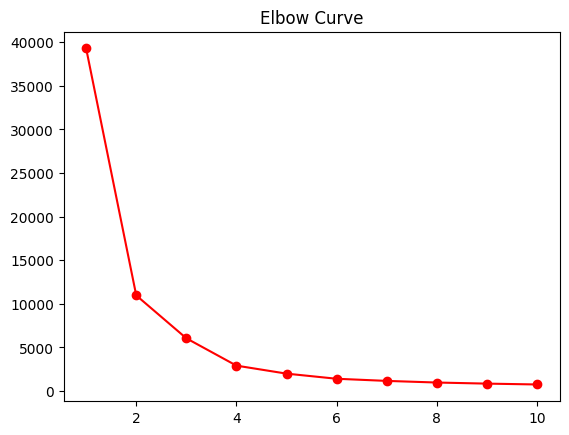

In [108]:
plt.plot(range(1,11), wcss, marker = 'o',color = 'Red')
plt.title('Elbow Curve')
plt.show()

In [109]:
k = 5
km_final = KMeans(n_clusters=k, init = 'k-means++', n_init = 10, random_state=42)
df['cluster']=km_final.fit_predict(x_scaled)
df

,Gender,Age,Annual Income (k$),Spending Score (1-100),cluster
0,1,19,15,39,4
1,1,21,15,81,2
2,0,20,16,6,4
3,0,23,16,77,2
4,0,31,17,40,4
...,...,...,...,...,...
195,0,35,120,79,1
196,0,45,126,28,3
197,1,32,126,74,1
198,1,32,137,18,3


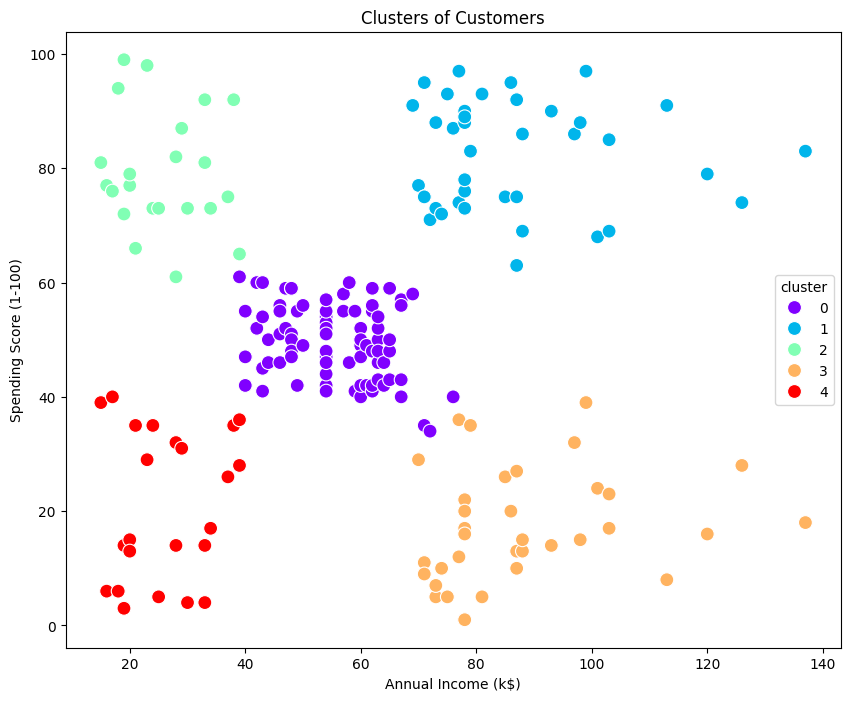

In [110]:
plt.figure(figsize=(10,8))
sns.scatterplot(data=df, x='Annual Income (k$)', y='Spending Score (1-100)', hue='cluster', palette='rainbow', s=100)
plt.title('Clusters of Customers')
plt.show()

In [111]:
km_final.cluster_centers_

array([[-0.20091257, -0.02645617],
       [ 0.99158305,  1.23950275],
       [-1.32954532,  1.13217788],
       [ 1.05500302, -1.28443907],
       [-1.30751869, -1.13696536]])

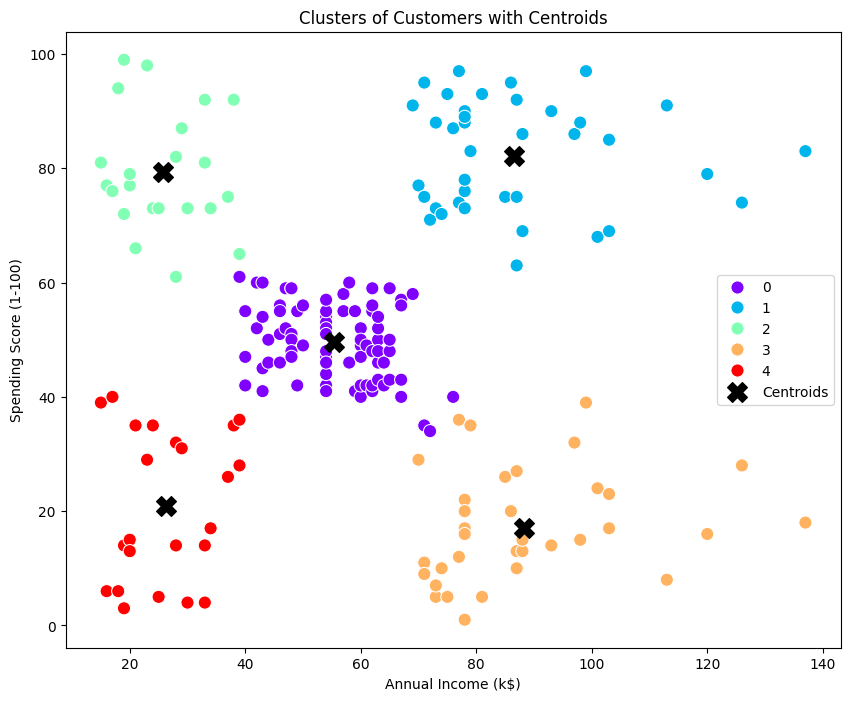

In [112]:
# Retrieve the scaled centroids from the KMeans model
scaled_centroids = km_final.cluster_centers_

# We inverse transform the entire 2D centroids array to map them back to the original scale
centroids_unscaled = std.inverse_transform(scaled_centroids)

# Create the scatter plot
plt.figure(figsize=(10,8))
sns.scatterplot(data=df, x='Annual Income (k$)', y='Spending Score (1-100)', hue='cluster', palette='rainbow', s=90)

# Overlay the centroids
plt.scatter(centroids_unscaled[:, 0], centroids_unscaled[:, 1], color='black', marker='X', s=200, label='Centroids')

plt.title('Clusters of Customers with Centroids')
plt.legend()
plt.show()

In [113]:
centroids_unscaled

array([[55.2962963 , 49.51851852],
       [86.53846154, 82.12820513],
       [25.72727273, 79.36363636],
       [88.2       , 17.11428571],
       [26.30434783, 20.91304348]])